In [1]:
import pandas as pd 
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans
import joblib
df = pd.read_csv("../tas2_yontem1.csv",encoding="utf-8")
yontem1df = df.copy()
yontem1df['max_price'] = df['max_price'].fillna(df['max_price'].median())
yontem1df['min_price'] = df['min_price'].fillna(df['min_price'].median())
yontem1df['gender'] = df['gender'].fillna("NULL")
yontem1df['message'] = df['message'].fillna("NULL")
yontem1df['comment'] = df['comment'].fillna("NULL")
yontem1df['deviceType'] = df['deviceType'].fillna("NULL")
yontem1df['categories'] = df['categories'].fillna("NULL")
yontem1df['contents'] = df['contents'].fillna("NULL")
df = yontem1df.copy()



numerical_features = df.select_dtypes(include=['float64', 'int64']).columns

categorical_features = df.select_dtypes(include=['object']).columns

ss = StandardScaler()
ohe = OneHotEncoder(handle_unknown='ignore')
preprocessor = ColumnTransformer(
    transformers=[
        ('num', ss, numerical_features),
        ('cat', ohe, categorical_features)
    ]
)

pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('clusterer', KMeans(n_clusters=3, random_state=42))
])
pipeline.fit(df)
labels = pipeline.named_steps['clusterer'].labels_
df['segment'] = labels

joblib.dump(pipeline, 'kmeans_3segment.pkl')

['kmeans_3segment.pkl']

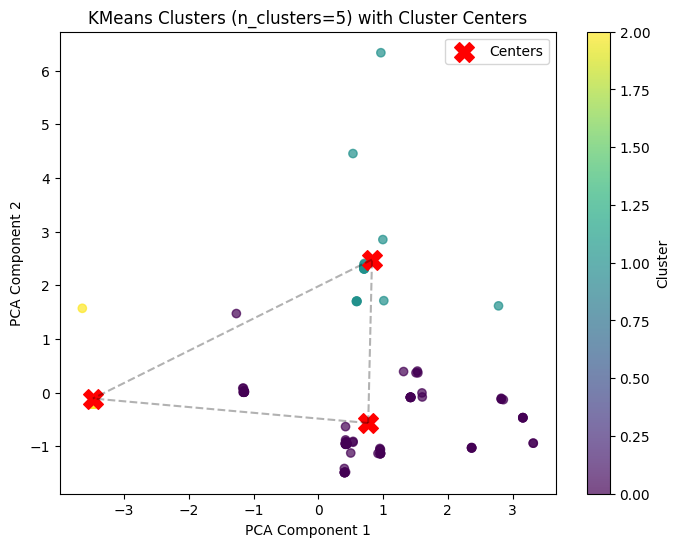

In [4]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Preprocessing sonrası veriyi al
X_transformed = pipeline.named_steps['preprocessor'].transform(df)

# PCA uygula (örneğin 2 bileşen)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_transformed)

# KMeans merkezlerini PCA uzayına dönüştür
centers = pipeline.named_steps['clusterer'].cluster_centers_
centers_pca = pca.transform(centers)

# Görselleştir
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df['segment'], cmap='viridis', alpha=0.7)
plt.scatter(centers_pca[:, 0], centers_pca[:, 1], c='red', marker='X', s=200, label='Centers')

for i in range(len(centers_pca)):
    for j in range(i + 1, len(centers_pca)):
        plt.plot([centers_pca[i, 0], centers_pca[j, 0]], [centers_pca[i, 1], centers_pca[j, 1]], 'k--', alpha=0.3)

plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.title('KMeans Clusters (n_clusters=5) with Cluster Centers')
plt.colorbar(scatter, label='Cluster')
plt.legend()
plt.show()
